# Dannyl MOUHEB – Modèle churn ClientCo – 1. Modèle mensuel (chiffres de la présentation)

**Ce que fait ce notebook**
1. Lit le CSV `data/dataset_sales_2026.csv` (ou le cache `dannyl_modele_churn/cache/agregats.pkl`).
2. Prend une **photo** du portefeuille le 1er de chaque mois (oct. 2023 → mars 2024) : pour chaque client régulier, 28 **features** calculées avant la date et les **cibles** observées après.
3. Sépare les clients : 80 % pour apprendre (photos d'oct. 2023 à janv. 2024), 20 % jamais vus pour tester (photo du 1er mars 2024).
4. Compare 3 modèles (règle simple, régression logistique, XGBoost) sur 3 cibles (départ total, forte baisse, les deux).
5. Évalue la **liste d'appels** (clients classés par probabilité × CA, coupés à la capacité des commerciaux) et valorise à l'échelle du groupe.

**Cibles** : départ total = aucun achat pendant 3 × le rythme habituel du client (entre 90 et 180 jours) ; forte baisse = CA du trimestre < 50 % du même trimestre l'an dernier et du trimestre moyen. Le détail de chaque feature est dans `dannyl_commun.py` (`DESCRIPTION_VARIABLES`).

**Sortie principale** : `dannyl_modele_churn/resultats/mensuel/resultats.json` (à envoyer pour mettre à jour les slides).

In [1]:
# --- Mise en place (ne pas modifier) -------------------------------------------------------------
# Le notebook se place à la racine du dépôt (où se trouve data/) et rend importables les modules
# du dossier dannyl_modele_churn.
import os, sys, json
import pandas as pd
from IPython.display import Image, display
if os.path.basename(os.getcwd()) == "dannyl_modele_churn":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("dannyl_modele_churn"))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RES = os.path.join("dannyl_modele_churn", "resultats")
print("Dossier de travail :", os.getcwd())

Dossier de travail : c:\Users\DanXVI\Desktop\CentraleSupélec\3A\M2AD\EDC 3\case_BCGX


## Paramètres
`CONTACTS_PAR_MOIS` : contacts anti-churn par commercial et par mois (hypothèse : 10 % du temps = 2 visites + 18 appels).

In [2]:
CONTACTS_PAR_MOIS = 20
PART_CLIENTS_TEST = 0.20

## Lancement (10 à 30 min au premier lancement pour lire les 4 Go, puis quelques minutes)

In [3]:
import importlib, dannyl_1_modele_mensuel as script
importlib.reload(script)
sys.argv = ["dannyl_1_modele_mensuel"] + ["--contacts-par-mois", str(CONTACTS_PAR_MOIS), "--part-clients-test", str(PART_CLIENTS_TEST)]
script.main()

Cache trouvé : c:\Users\DanXVI\Desktop\CentraleSupélec\3A\M2AD\EDC 3\case_BCGX\dannyl_modele_churn\cache\agregats.pkl

== Représentativité ==
  periode_debut: 2022-09-22
  periode_fin: 2024-09-22
  lignes: 63319315
  doublons: 1488779
  lignes_neg: 2334447
  ca_retours_meur: 567.3
  lignes_nulles: 2283659
  produits: 607418
  clients: 170589
  agences: 582
  ca_dataset_12m_meur: 4685.0
  part_ca_groupe: 0.302
  ca_dataset_2023_meur: 4532.0
  part_ca_groupe_2023: 0.292
  facteur_groupe: 3.42
  part_agences: 0.582
  clients_actifs_12m: 142228
  part_clients: 0.316

Photos : ['2023-10', '2023-11', '2023-12', '2024-01', '2024-02', '2024-03'] | apprentissage <= 2024-01, test = 2024-03
  churn_total    | Règle métier (silence vs rythme habituel)  | AUC 0.602 | précision 0.09 | CA à risque capté 0.325
  churn_total    | Régression logistique                      | AUC 0.833 | précision 0.198 | CA à risque capté 0.453
  churn_total    | Gradient boosting (XGBoost)                | AUC 0.844 | 

## Résultats
### Représentativité du dataset et capacité commerciale

In [4]:
R = json.load(open(os.path.join(RES, "mensuel", "resultats.json"), encoding="utf-8"))
display(pd.Series(R["dataset"], name="dataset").to_frame())
display(pd.Series(R["capacite"], name="capacité").to_frame())

,dataset
periode_debut,2022-09-22
periode_fin,2024-09-22
lignes,63319315
doublons,1488779
lignes_neg,2334447
ca_retours_meur,567.3
lignes_nulles,2283659
produits,607418
clients,170589
agences,582


,capacité
reps_groupe,200.000
part_groupe,0.292
reps_dataset,58.400
contacts_par_mois,20.000
liste_mensuelle,1168.000
liste_trimestre,3504.000
liste_trimestre_test,702.000
part_clients_test,0.200
contacts_an_groupe,48000.000
part_clients_eligibles_contactes_trim,0.039


### Combien de clients partent ? (photo du 1er mars 2024, tous les clients réguliers)

In [5]:
display(pd.DataFrame(R["churn_descriptif"]).T)
display(pd.Series(R["silence_vs_rythme"], name="part des clients selon silence / rythme habituel").to_frame())

,pct_clients,nb_clients,ca_ref_moyen_trim_keur,perte_trim_meur,part_ca_ref,ca_risque_an_groupe_meur
churn_total,0.144,13072.0,2.1,26.76,0.027,367.0
churn_partiel,0.157,14177.0,9.6,104.24,0.104,1428.0
churn,0.301,27249.0,6.0,131.00,0.131,1795.0


,part des clients selon silence / rythme habituel
< 1x,0.425
1-2x,0.263
2-3x,0.123
3-5x,0.098
> 5x,0.090


### Performance des modèles (clients et période jamais vus)
- **perte_captee_k** : part du CA à risque captée par la liste d'appels (indicateur principal)
- **precision_k** : sur 100 clients appelés, combien partent vraiment ; **rappel_k_gros** : part des gros clients qui partent présents dans la liste
- **auc / pr_auc / brier** : qualité du classement et des probabilités

In [6]:
lignes = []
for cible, d in R["metriques"].items():
    for modele, m in d.items():
        lignes.append(dict(cible=cible, modele=modele, **{k: v for k, v in m.items() if k not in ("confusion", "perte_captee_k_meur")}))
display(pd.DataFrame(lignes).set_index(["cible", "modele"]))
print("Modèle retenu :", R["modele_retenu"])
print("Intervalle de confiance à 90 % du CA à risque capté :", R["intervalle_90_perte_captee"])

auc  pr_auc   brier  taux_base  precision_k  rappel_k  perte_captee_k  rappel_k_gros
cible         modele                                                                                                                           
churn_total   Règle métier (silence vs rythme habituel)  0.602   0.230  0.1368      0.144        0.090     0.024           0.325          0.562
              Régression logistique                      0.833   0.398  0.1835      0.144        0.198     0.053           0.453          0.808
              Gradient boosting (XGBoost)                0.844   0.422  0.0987      0.144        0.275     0.074           0.505          0.849
churn_partiel Règle métier (silence vs rythme habituel)  0.526   0.175  0.1501      0.155        0.209     0.053           0.347          0.224
              Régression logistique                      0.772   0.323  0.2016      0.155        0.189     0.048           0.398          0.229
              Gradient boosting (XGBoost)                0.793   0.371  0.1123      0.155        0.332     0.083           0.466          0.401
churn         Règle métier (silence vs rythme habituel)  0.576   0.396  0.2853      0.299        0.299     0.039           0.343          0.261
              Régression logistique                      0.757   0.547  0.1983      0.299        0.295     0.038           0.397          0.317
              Gradient boosting (XGBoost)                0.771   0.569  0.1701      0.299        0.436     0.057           0.440          0.451

Modèle retenu : Gradient boosting (XGBoost)
Intervalle de confiance à 90 % du CA à risque capté : [0.404, 0.479]


### Matrice de confusion de la liste d'appels (modèle retenu, cible principale)

In [7]:
c = R["metriques"]["churn"][R["modele_retenu"]]["confusion"]
display(pd.DataFrame([[c["vrais_positifs"], c["faux_positifs"]], [c["departs_manques"], c["vrais_negatifs"]]],
                     index=["Dans la liste", "Hors liste"], columns=["Partent vraiment", "Restent"]))

,Partent vraiment,Restent
Dans la liste,306,396
Hors liste,5096,12257


### Courbe de gain et calibration

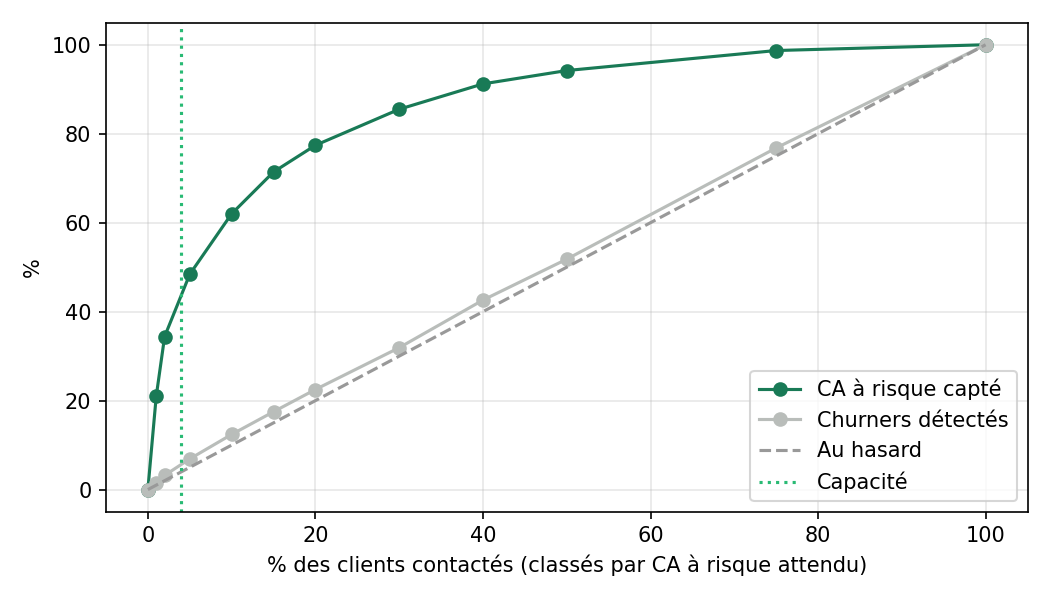

,bin,proba_predite,taux_observe,n
0,0,0.027,0.018,1806
1,1,0.073,0.065,1805
2,2,0.131,0.128,1806
3,3,0.190,0.193,1805
4,4,0.250,0.265,1806
5,5,0.312,0.328,1805
6,6,0.373,0.364,1805
7,7,0.439,0.431,1806
8,8,0.518,0.528,1805
9,9,0.652,0.672,1806


In [8]:
display(Image(os.path.join(RES, "mensuel", "courbe_gain.png")))
if "calibration" in R:
    display(pd.DataFrame(R["calibration"]))

### Lecture métier, valeur et features les plus utiles

In [9]:
display(pd.Series(R["lecture"], name="lecture").to_frame())
display(pd.Series(R["valeur"], name="valeur (M€ / an, groupe)").to_frame())
display(pd.Series(R.get("importance_variables", {}), name="importance (permutation, PR-AUC)").to_frame())

,lecture
sur_100_signales_partent,44.000
sur_10_churners_detectes,0.600
part_perte_captee,0.440
rappel_gros_clients,0.451
part_total_dans_liste,0.203
part_partiel_dans_liste,0.797
departs_atteints_an_groupe,20928.000


,"valeur (M€ / an, groupe)"
ca_a_risque_an_groupe_meur,1746.000
ca_a_risque_an_pct_ca,0.113
ca_a_risque_dans_liste_an_groupe_meur,769.000
marge_max_meur,189.900
marge_potentiel_theorique_meur,431.300
marge_recup_10_meur,19.000
marge_recup_25_meur,47.500
marge_recup_50_meur,94.900
marge_max_10contacts_meur,146.000
marge_max_20contacts_meur,189.900


,"importance (permutation, PR-AUC)"
indice_saison,0.0782
ca_1m,0.0213
ca_meme_trim_n1,0.0124
jours_3m,0.0119
jours_1m,0.0110
jours_12m,0.0101
tendance_6m,0.0081
recence_j,0.0080
recence_ratio,0.0072
tendance_3m,0.0061


### Exemple de liste d'appels mensuelle

In [10]:
display(pd.read_csv(os.path.join(RES, "mensuel", "liste_appels_exemple.csv"), sep=";").head(20))

,client_id,score,ca_12m,perte_attendue,recence_j,delai_median,tendance_3m,parti_en_realite,action
0,1552980,0.130874,5335224.50,196549.530,2.0,1.0,7.242962e-01,0,Visite
1,1695103,0.935446,432942.47,187044.190,59.0,4.0,5.488857e-01,1,Visite
2,988682,0.863614,433451.66,165215.360,22.0,3.0,3.164607e+00,1,Visite
3,1621313,0.988152,526921.70,134996.550,67.0,1.0,1.282323e-01,1,Visite
4,1744230,0.763884,478021.28,123757.695,2.0,1.0,3.862167e-01,1,Visite
5,977478,0.775015,496481.75,111980.580,4.0,1.0,8.742573e-02,1,Visite
6,417576,0.030065,13386365.00,99197.980,2.0,1.0,8.761396e-01,0,Visite
7,334549,0.776254,208870.12,92355.940,10.0,5.0,1.365157e+00,1,Visite
8,992720,0.278594,950777.70,88869.320,2.0,1.0,1.129536e+00,0,Visite
9,1947481,0.946092,210707.03,87315.195,85.0,2.0,1.737952e-01,1,Visite
